# Chapter 4 - Data Preparation and Feature Engineering

**Dataset:** Default of Credit Card Clients (UCI Machine Learning Repository, ID 350).
**Objective of this notebook:** turn the raw 30,000-row file audited in Chapter 3 into three
leakage-safe model matrices, one per split, together with a frozen feature list and a frozen set of
scaling parameters.

The order of operations is deliberate and is the main defence against data leakage:

| Step | Applied to | Why this order |
|---|---|---|
| Duplicate removal | all rows | duplicates must not be split across train and test |
| Recoding and encoding | all rows | pure look-up tables, no statistics estimated |
| Feature engineering | all rows | row-wise arithmetic, no cross-row statistics |
| Split 70/15/15 | all rows | everything below sees the training split only |
| Log transform | all splits | parameter-free, so it cannot leak |
| StandardScaler | **fit on train only** | mean and scale are estimated statistics |
| Pearson top-15 | **train only** | uses the labels, so it must never see validation or test |

Two techniques required by the brief are **not** applied and are argued in Section 4.5 of the report:
PCA (rejected: destroys the interpretability required for the Chapter 7 ensemble) and SMOTE
(rejected: linear interpolation would create non-existent ordinal codes and would alter the class
prior). Class imbalance is handled later by class weighting.

Outputs: `bank/data_processed/train.csv`, `val.csv`, `test.csv`, `scaler_params.csv`,
`preprocessing_spec.json`, and `bank/outputs/chapter_04/fig_4_2_log_transform.png`.

In [1]:
# ---------------------------------------------------------------------------
# 0. Setup: imports, portable paths, fixed seed
# ---------------------------------------------------------------------------
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Paths are relative to this notebook (bank/notebook/), so nothing is machine-specific.
DATA_PATH = Path("..") / "UCI_Credit_Card.csv"
DATA_DIR = Path("..") / "data_processed"
FIG_DIR = Path("..") / "outputs" / "chapter_04"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "default.payment.next.month"
ID_COL = "ID"
SEED = 42

np.random.seed(SEED)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

In [2]:
# 1. Load the raw file exactly as audited in Chapter 3.
df = pd.read_csv(DATA_PATH)

feature_cols = [c for c in df.columns if c not in (ID_COL, TARGET)]
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]

print(f"Raw shape        : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Predictors       : {len(feature_cols)}")
print(f"Default rate     : {df[TARGET].mean() * 100:.2f}%")

Raw shape        : 30,000 rows x 25 columns
Predictors       : 23
Default rate     : 22.12%


## 4.1 Duplicate removal and missing-value assessment

Chapter 3 found 52 groups of identical profiles (108 rows). Only the **35 fully duplicated records**
are removed here: they repeat both the 23 predictors and the label, so keeping them would allow the
same record to appear in both the training and the test split. The 21 profiles that carry **both**
labels are kept, because deleting them would silently remove genuine outcome information.
No missing values were found, so no imputation is required.

In [3]:
# 1a. Count the duplicates before touching anything.
n_before = len(df)
rate_before = df[TARGET].mean() * 100
n_dup_exact = int(df.duplicated(subset=feature_cols + [TARGET]).sum())

# 1b. Drop only the exact duplicates (same predictors AND same label).
df = df.drop_duplicates(subset=feature_cols + [TARGET]).reset_index(drop=True)
n_after = len(df)

print(f"Rows before      : {n_before:,}")
print(f"Exact duplicates : {n_dup_exact}")
print(f"Rows after       : {n_after:,}")
print(f"Missing values   : {int(df[feature_cols + [TARGET]].isna().sum().sum())}")

# 1c. Confirm that the class balance barely moves.
print(f"\nDefault rate before: {rate_before:.2f}%")
print(f"Default rate after : {df[TARGET].mean() * 100:.2f}%")
print("\nClass counts after cleaning:")
print(df[TARGET].value_counts().sort_index().to_string())

Rows before      : 30,000
Exact duplicates : 35
Rows after       : 29,965
Missing values   : 0

Default rate before: 22.12%
Default rate after : 22.13%

Class counts after cleaning:
default.payment.next.month
0    23335
1     6630


## 4.2 Recoding and encoding

Chapter 3 showed that `EDUCATION` uses the undocumented codes 0, 5 and 6 (345 rows) and `MARRIAGE`
uses 0 (54 rows). Each of these codes is extremely sparse, so they are merged into the existing
residual category: 0, 5 and 6 become 4 ("others") and `MARRIAGE` 0 becomes 3. The three categorical
variables are then label encoded, which keeps the matrix at 23 columns and gives all three models in
Chapter 5 an identical input space.

In [4]:
# 2a. Merge the undocumented codes into the residual category reported in the codebook.
edu_before = df["EDUCATION"].value_counts().sort_index().to_dict()
mar_before = df["MARRIAGE"].value_counts().sort_index().to_dict()

df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

print("EDUCATION before:", edu_before)
print("EDUCATION after :", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE before :", mar_before)
print("MARRIAGE after  :", df["MARRIAGE"].value_counts().sort_index().to_dict())

# 2b. Default rate per category, to check that the merged groups behave sensibly.
for col in cat_cols:
    rates = df.groupby(col)[TARGET].mean().mul(100).round(2)
    print(f"\nDefault rate by {col} (%):")
    print(rates.to_string())

EDUCATION before: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
EDUCATION after : {1: 10563, 2: 14019, 3: 4915, 4: 468}
MARRIAGE before : {0: 54, 1: 13643, 2: 15945, 3: 323}
MARRIAGE after  : {1: 13643, 2: 15945, 3: 377}

Default rate by SEX (%):
SEX
1    24.16
2    20.79

Default rate by EDUCATION (%):
EDUCATION
1    19.24
2    23.74
3    25.17
4     7.05

Default rate by MARRIAGE (%):
MARRIAGE
1    23.46
2    20.95
3    23.61


In [5]:
# 2c. Label encoding: replace each category by an integer position starting at 0.
#     A plain dictionary is used so the mapping is explicit and can be reproduced.
label_maps = {
    "SEX": {1: 0, 2: 1},
    "EDUCATION": {1: 0, 2: 1, 3: 2, 4: 3},
    "MARRIAGE": {1: 0, 2: 1, 3: 2},
}

for col, mapping in label_maps.items():
    df[col] = df[col].map(mapping)

print("Encoding maps:")
for col, mapping in label_maps.items():
    print(f"  {col:10s} {mapping}")
print("\nAny unmapped value left?", df[cat_cols].isna().sum().sum())

Encoding maps:
  SEX        {1: 0, 2: 1}
  EDUCATION  {1: 0, 2: 1, 3: 2, 4: 3}
  MARRIAGE   {1: 0, 2: 1, 3: 2}

Any unmapped value left? 0


## 4.3 Feature engineering

Eight features are added. Each is computed **row by row**, so it uses no information from other
clients and cannot leak across the split. Two of them are ratios, which are clipped to [0, 2]: values
above 2 come from very small denominators and carry little information, and the raw amounts remain
in the matrix anyway. `+1` in the denominators keeps the division defined when a bill is zero.

In [6]:
# 3a. Ratios ---------------------------------------------------------------
# Credit utilisation: how much of the granted limit is currently used.
df["utilization"] = (df["BILL_AMT1"] / df["LIMIT_BAL"]).clip(0, 2)

# Share of the previous month's bill that was actually paid in September.
# BILL_AMT2 is used because Section 4.4 shows that PAY_AMT1 settles the previous
# bill: of positive balances, 15.15% repay BILL_AMT2 in full against 2.43% for BILL_AMT1.
df["payment_ratio_1"] = (df["PAY_AMT1"] / (df["BILL_AMT2"].clip(lower=0) + 1)).clip(0, 2)

# 3b. Six-month aggregates ------------------------------------------------
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
status_cols = ["PAY_0"] + [f"PAY_{i}" for i in range(2, 7)]

df["avg_bill"] = df[bill_cols].mean(axis=1)
df["avg_pay"] = df[pay_cols].mean(axis=1)

# 3c. Delinquency summaries ----------------------------------------------
df["delinq_count"] = (df[status_cols] > 0).sum(axis=1)   # months with any delay
df["max_delay"] = df[status_cols].max(axis=1)            # worst delay code

# 3d. Direction of travel over the six months -----------------------------
df["bill_trend"] = df["BILL_AMT1"] - df["BILL_AMT6"]
df["pay_trend"] = df["PAY_AMT1"] - df["PAY_AMT6"]

engineered = ["utilization", "payment_ratio_1", "avg_bill", "avg_pay",
              "delinq_count", "max_delay", "bill_trend", "pay_trend"]

print(f"Engineered features: {len(engineered)}")
print(f"Total predictors now: {len(feature_cols) + len(engineered)}")

# Quick signal check: correlation of each new feature with the target.
signal = df[engineered].corrwith(df[TARGET]).sort_values(key=np.abs, ascending=False)
print("\nCorrelation with the target (Pearson):")
print(signal.round(3).to_string())

# Evidence for the denominator choice above: exact repayment of each statement.
bill2_pos = df["BILL_AMT2"] > 0
bill1_pos = df["BILL_AMT1"] > 0
paid_exact2 = (df.loc[bill2_pos, "PAY_AMT1"] == df.loc[bill2_pos, "BILL_AMT2"]).mean() * 100
paid_exact1 = (df.loc[bill1_pos, "PAY_AMT1"] == df.loc[bill1_pos, "BILL_AMT1"]).mean() * 100
print(f"\nExact repayment of BILL_AMT2 (positive balances): {paid_exact2:.2f}%")
print(f"Exact repayment of BILL_AMT1 (positive balances): {paid_exact1:.2f}%")

Engineered features: 8
Total predictors now: 31

Correlation with the target (Pearson):
delinq_count       0.398
max_delay          0.331
payment_ratio_1   -0.118
avg_pay           -0.102
utilization        0.088
bill_trend        -0.026
avg_bill          -0.013
pay_trend         -0.012

Exact repayment of BILL_AMT2 (positive balances): 15.15%
Exact repayment of BILL_AMT1 (positive balances): 2.43%


## 4.4 Stratified 70/15/15 split

The split happens **after** cleaning and feature engineering but **before** any scaling or feature
selection. Sizes are fixed as integers so that the training, validation and test sets are exactly
70%, 15% and 15% of 29,965 rows.

In [7]:
# 4a. Fixed integer sizes: 20,975 / 4,495 / 4,495.
n_total = len(df)
n_test = int(round(0.15 * n_total))
n_val = n_test

df_trainval, df_test = train_test_split(
    df, test_size=n_test, stratify=df[TARGET], random_state=SEED)

df_train, df_val = train_test_split(
    df_trainval, test_size=n_val, stratify=df_trainval[TARGET], random_state=SEED)

# 4b. Every split must keep the same default rate as the full sample.
for name, part in [("train", df_train), ("validation", df_val), ("test", df_test)]:
    print(f"{name:11s} rows {len(part):6,d}   default {int(part[TARGET].sum()):5,d}   "
          f"rate {part[TARGET].mean() * 100:5.2f}%")

train       rows 20,975   default 4,641   rate 22.13%
validation  rows  4,495   default   994   rate 22.11%
test        rows  4,495   default   995   rate 22.14%


## 4.5 Feature scaling

The monetary columns are strongly right-skewed, so a signed `log1p` is applied first; the sign is kept
because `BILL_AMT` contains negative credit balances. `StandardScaler` is then fitted on the training
set only and applied unchanged to the validation and test sets. The repayment-status codes and the
encoded categoricals are left untouched: they are bounded ordinal values whose meaning would be
destroyed by rescaling.

In [8]:
# 5a. Which columns are transformed, and how.
log_cols = ["LIMIT_BAL"] + bill_cols + pay_cols + ["avg_bill", "avg_pay", "bill_trend", "pay_trend"]
scale_only_cols = ["AGE", "utilization", "payment_ratio_1"]
scale_cols = log_cols + scale_only_cols

model_features = feature_cols + engineered
passthrough_cols = [c for c in model_features if c not in scale_cols]

print(f"log1p + scale : {len(log_cols)}")
print(f"scale only    : {len(scale_only_cols)}")
print(f"left as is    : {len(passthrough_cols)}  -> {passthrough_cols}")


def signed_log1p(frame, columns):
    # sign(x) * log(1 + |x|): monotone, defined for negative bills, keeps the sign.
    out = frame.copy()
    out[columns] = np.sign(frame[columns]) * np.log1p(np.abs(frame[columns]))
    return out


# 5b. The log transform has no parameters, so it can be applied to every split.
train = signed_log1p(df_train, log_cols)
val = signed_log1p(df_val, log_cols)
test = signed_log1p(df_test, log_cols)

# 5c. The scaler is fitted on the training set only.
scaler = StandardScaler().fit(train[scale_cols])

train[scale_cols] = scaler.transform(train[scale_cols])
val[scale_cols] = scaler.transform(val[scale_cols])
test[scale_cols] = scaler.transform(test[scale_cols])

print("\nTraining means after scaling (should be ~0):")
print(np.round(train[scale_cols].mean().values[:5], 12))
print("Training stds after scaling (should be 1):")
print(np.round(train[scale_cols].std(ddof=0).values[:5], 12))

log1p + scale : 17
scale only    : 3
left as is    : 11  -> ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'delinq_count', 'max_delay']

Training means after scaling (should be ~0):
[ 0.  0. -0. -0.  0.]
Training stds after scaling (should be 1):
[1. 1. 1. 1. 1.]


## 4.6 Feature selection

Three sets are defined so that the contribution of the new features can be measured:

- **A** - the 23 original predictors.
- **B** - A plus the 8 engineered features (31).
- **C** - the 15 features of B with the largest absolute Pearson correlation with the target.

The correlation is computed **on the training split only**, once, and the resulting list is frozen for
Chapters 5 to 8.

In [9]:
# 6a. Pearson correlation with the target, training set only.
pearson = train[model_features + [TARGET]].corr()[TARGET].drop(TARGET)
pearson = pearson.reindex(pearson.abs().sort_values(ascending=False).index)

top15 = pearson.head(15).index.tolist()

feature_sets = {
    "A": feature_cols,          # 23 original predictors
    "B": model_features,        # 31 = 23 + 8 engineered
    "C": top15,                 # 15 = top 15 of B by |Pearson r|
}

print("Top 15 predictors by |r| with the target (training set):")
print(pearson.head(15).round(3).to_string())
print(f"\nSet sizes -> A: {len(feature_sets['A'])}  B: {len(feature_sets['B'])}  C: {len(feature_sets['C'])}")

Top 15 predictors by |r| with the target (training set):
delinq_count       0.400
max_delay          0.334
PAY_0              0.325
PAY_2              0.266
PAY_3              0.236
PAY_4              0.217
PAY_5              0.205
PAY_6              0.187
LIMIT_BAL         -0.175
PAY_AMT1          -0.175
PAY_AMT2          -0.153
avg_pay           -0.153
PAY_AMT3          -0.140
PAY_AMT4          -0.125
payment_ratio_1   -0.122

Set sizes -> A: 23  B: 31  C: 15


## 4.7 Baseline comparison of the three feature sets

A single untuned Random Forest is used to measure whether the engineered features and the correlation
filter actually help. This is a **feature-set comparison only**; hyperparameter tuning belongs to
Chapter 6, so the defaults are kept and no class weighting is applied.

In [10]:
# 7a. One fixed, untuned baseline so that only the feature set changes.
def evaluate_feature_set(name, columns):
    model = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
    model.fit(train[columns], train[TARGET])

    pred = model.predict(val[columns])
    proba = model.predict_proba(val[columns])[:, 1]

    return {
        "Feature set": name,
        "Features": len(columns),
        "Accuracy": accuracy_score(val[TARGET], pred),
        "Precision": precision_score(val[TARGET], pred),
        "Recall": recall_score(val[TARGET], pred),
        "F1": f1_score(val[TARGET], pred),
        "ROC-AUC": roc_auc_score(val[TARGET], proba),
    }


table_4_4 = pd.DataFrame([
    evaluate_feature_set("A (original)", feature_sets["A"]),
    evaluate_feature_set("B (original + engineered)", feature_sets["B"]),
    evaluate_feature_set("C (top 15 by |r|)", feature_sets["C"]),
]).round(4)

table_4_4

,Feature set,Features,Accuracy,Precision,Recall,F1,ROC-AUC
0,A (original),23,0.8131,0.6375,0.3592,0.4595,0.7604
1,B (original + engineered),31,0.8122,0.6325,0.3602,0.4590,0.7544
2,C (top 15 by |r|),15,0.8116,0.6252,0.3692,0.4643,0.7537


## 4.7b Encoding check

Section 4.2 chose label encoding for the three categorical variables. The check below
holds the forest and the 23 predictors of set A fixed and changes only that encoding,
dropping one reference level so that the dummy columns do not sum to the intercept.

In [11]:
# 7b. Same forest and same predictors as 7a; only the encoding of the three
# categorical columns changes. drop_first removes the reference level, so the
# dummy columns no longer sum to the intercept.
CATEGORICAL = ["SEX", "EDUCATION", "MARRIAGE"]

def one_hot(frame):
    return pd.get_dummies(frame, columns=CATEGORICAL, drop_first=True, dtype=float)

train_oh = one_hot(train)
val_oh = one_hot(val).reindex(columns=train_oh.columns, fill_value=0.0)

categorical_oh = [c for c in train_oh.columns
                  if any(c.startswith(f"{name}_") for name in CATEGORICAL)]
set_a_label = feature_sets["A"]
set_a_oh = [c for c in set_a_label if c not in CATEGORICAL] + categorical_oh

encoding_rows = []
for name, frame_train, frame_val, columns in [
    ("Label", train, val, set_a_label),
    ("One-hot", train_oh, val_oh, set_a_oh),
]:
    model = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
    model.fit(frame_train[columns], frame_train[TARGET])
    proba = model.predict_proba(frame_val[columns])[:, 1]
    encoding_rows.append({
        "Encoding": name,
        "Categorical columns": len(CATEGORICAL) if name == "Label" else len(categorical_oh),
        "Set A predictors": len(columns),
        "Validation AUC": roc_auc_score(frame_val[TARGET], proba),
    })

encoding_check = pd.DataFrame(encoding_rows).round(4)
encoding_check.to_csv(FIG_DIR / "encoding_check.csv", index=False)
encoding_check

,Encoding,Categorical columns,Set A predictors,Validation AUC
0,Label,3,23,0.7604
1,One-hot,6,26,0.7597


## 4.8 Figure 4.2: effect of the signed log transform

One heavy-tailed predictor is shown before and after the transform to document that the scaling step is
necessary and that it does not distort the shape of the distribution.

Share of clients with PAY_AMT2 == 0: 17.90%


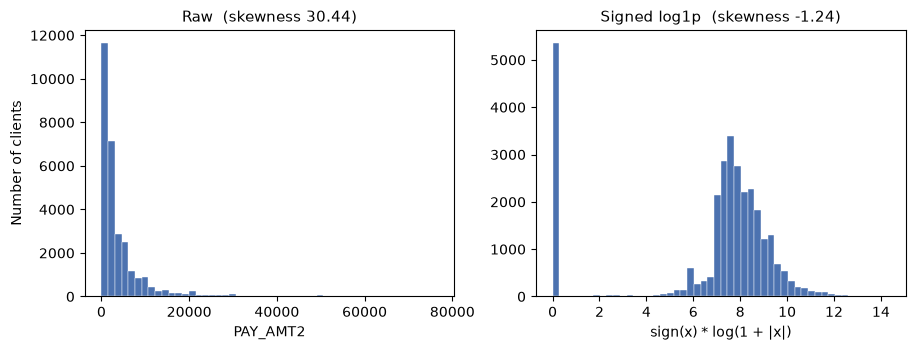

In [12]:
# 8a. Before/after comparison for the most skewed predictor (PAY_AMT2, skewness 30.44).
col = "PAY_AMT2"
raw_values = df[col].values
transformed = np.sign(raw_values) * np.log1p(np.abs(raw_values))
zero_share = float((raw_values == 0).mean() * 100)
print(f"Share of clients with PAY_AMT2 == 0: {zero_share:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6))

# Left: raw values, clipped to the 99th percentile for display only.
axes[0].hist(raw_values, bins=50, range=(0, np.percentile(raw_values, 99)),
             color="#4C72B0", edgecolor="white", linewidth=0.3)
axes[0].set_title(f"Raw  (skewness {pd.Series(raw_values).skew():.2f})", fontsize=11)
axes[0].set_xlabel("PAY_AMT2")
axes[0].set_ylabel("Number of clients")

# Right: after the signed log1p used in the pipeline.
axes[1].hist(transformed, bins=50, color="#4C72B0", edgecolor="white", linewidth=0.3)
axes[1].set_title(f"Signed log1p  (skewness {pd.Series(transformed).skew():.2f})", fontsize=11)
axes[1].set_xlabel("sign(x) * log(1 + |x|)")

fig.tight_layout()
fig.savefig(FIG_DIR / "fig_4_2_log_transform.png")
plt.show()

## 4.9 Saving the frozen artifacts

The three processed splits are written for Chapter 5, together with the scaling parameters (plain CSV,
no pickle) and a small JSON file that records every decision needed to reproduce the pipeline.

In [13]:
# 9a. Keep ID for traceability, then the model columns in a fixed order, then the target.
columns_out = [ID_COL] + model_features + [TARGET]

train[columns_out].to_csv(DATA_DIR / "train.csv", index=False)
val[columns_out].to_csv(DATA_DIR / "val.csv", index=False)
test[columns_out].to_csv(DATA_DIR / "test.csv", index=False)

# 9b. Scaling parameters as a readable table.
scaler_params = pd.DataFrame({
    "feature": scale_cols,
    "mean": scaler.mean_,
    "scale": scaler.scale_,
    "transform": ["log1p+scale"] * len(log_cols) + ["scale"] * len(scale_only_cols),
})
scaler_params.round(6).to_csv(DATA_DIR / "scaler_params.csv", index=False)

# 9c. Everything else that is needed to rebuild the pipeline later.
spec = {
    "random_state": SEED,
    "rows_raw": int(n_before),
    "rows_after_dedup": int(n_after),
    "split": {"train": int(len(train)), "validation": int(len(val)), "test": int(len(test))},
    "target": TARGET,
    "identifier": ID_COL,
    "engineered_features": engineered,
    "feature_sets": feature_sets,
    "selected_set": "A",
    "transform": {
        "log1p_then_scale": log_cols,
        "scale_only": scale_only_cols,
        "passthrough": passthrough_cols,
    },
}
(DATA_DIR / "preprocessing_spec.json").write_text(
    json.dumps(spec, indent=2), encoding="utf-8")

print("Saved files:")
for path in sorted(DATA_DIR.glob("*")):
    print(f"  {path.name:28s} {(path.stat().st_size / 1024):8.1f} KB")
print(f"  {FIG_DIR.name}/fig_4_2_log_transform.png")

Saved files:
  model_results                     4.0 KB
  predictions                       4.0 KB
  preprocessing_spec.json           2.4 KB
  scaler_params.csv                 0.8 KB
  test.csv                       1855.8 KB
  train.csv                      8654.7 KB
  val.csv                        1855.1 KB
  chapter_04/fig_4_2_log_transform.png


## 4.10 Preprocessing impact summary

Table 4.5 in the report draws the preprocessing decisions together. The measured effects are the
duplicate default-rate shift, the skewness reduction from the signed log, and the A/B/C feature-set
AUC deltas. The remaining entries are theoretical because those steps are correctness controls or
were rejected before fitting; the feature-set experiment is the pipeline-level ablation.